In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor

pd.set_option("display.precision", 4)

Load data and define inputs and outpus

In [10]:
col_names=['Frequency_Hz','Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m','Scaled_sound_pressure_level_dB']
df = pd.read_csv(
    "../data/airfoil_self_noise.dat",
    sep=r"\s+",
    header=None,
    names=col_names
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(df.head())

X = df.iloc[:, 0:5]
y = df.iloc[:, 5]



   Frequency_Hz  Angle_of_attack_deg  Chord_length_m  Free_stream_velocity_m/s  Suction_side_displacement_thickness_m  Scaled_sound_pressure_level_dB
0           800                  0.0          0.3048                      71.3                                 0.0027                         126.201
1          1000                  0.0          0.3048                      71.3                                 0.0027                         125.201
2          1250                  0.0          0.3048                      71.3                                 0.0027                         125.951
3          1600                  0.0          0.3048                      71.3                                 0.0027                         127.591
4          2000                  0.0          0.3048                      71.3                                 0.0027                         127.461


Data cleaning

In [11]:
#Check the basic structure of data
print("Shape: ")
print("DataFrame shape: ",df.shape)
print("X shape: ",X.shape)
print("Y shape: ",y.shape)
print("------------------------------------------")
#Check data type for each entry
print("Data type:\n",df.dtypes,sep="")
print("------------------------------------------")
#Chek missing values
print("Missing value count:\n",df.isnull().sum(),sep="")
print("------------------------------------------")
#Check duplicated rows
print("Duplicated rows:",df.duplicated().sum())
print("------------------------------------------")
#Check the overall statistics of data
print(df.describe())

Shape: 
DataFrame shape:  (1503, 6)
X shape:  (1503, 5)
Y shape:  (1503,)
------------------------------------------
Data type:
Frequency_Hz                               int64
Angle_of_attack_deg                      float64
Chord_length_m                           float64
Free_stream_velocity_m/s                 float64
Suction_side_displacement_thickness_m    float64
Scaled_sound_pressure_level_dB           float64
dtype: object
------------------------------------------
Missing value count:
Frequency_Hz                             0
Angle_of_attack_deg                      0
Chord_length_m                           0
Free_stream_velocity_m/s                 0
Suction_side_displacement_thickness_m    0
Scaled_sound_pressure_level_dB           0
dtype: int64
------------------------------------------
Duplicated rows: 0
------------------------------------------
       Frequency_Hz  Angle_of_attack_deg  Chord_length_m  Free_stream_velocity_m/s  Suction_side_displacement_thickness_m  S

Split the data into train, validation and test set using group split becasue the experiment is about obtaining a spectrum of frequency, then analyze their spl, for different type of NACA0012 sizes and angle of attack. 

In [12]:
categorical_feature = ['Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m']
#Take the value of the categorical_feature column and convert them into a tuple. Assign each unique tuple (unique) with an ID (groups).
groups, unique = pd.factorize(X[categorical_feature].apply(tuple, axis=1))

#Split data into train, validation and test set, ratio of 60:20:20
#Use Group Split to split data once into train+validation and test set, ratio of 80:20
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
#Split the data and obtain the row idx for train_validation and test set
train_val_idx, test_idx = next(gss_test.split(X, y, groups=groups))

#Extract the data to their corresponding idx
X_train_val, X_test = X.iloc[train_val_idx], X.iloc[test_idx]
y_train_val, y_test = y.iloc[train_val_idx], y.iloc[test_idx]

#Use same procedure split train and validation set, ratio of 25:75
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
#Split the data and obtain the row idx for train and validation set
train_idx, val_idx = next(gss_val.split(X_train_val, y_train_val, groups=groups[train_val_idx]))
#Extract the data to their corresponding idx
X_train, X_val = X_train_val.iloc[train_idx], X_train_val.iloc[val_idx]
y_train, y_val= y_train_val.iloc[train_idx], y_train_val.iloc[val_idx]

Fit Linear Regression to fit data

In [13]:
#Train Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

#Report the intercept and coefficient in a data frame
coefficient_table = pd.DataFrame({
    "parameter": ['intercept', 'Frequency', 'Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m'],
    "value": [linear_model.intercept_.item()] + list(linear_model.coef_.ravel()),
    "units": ["dB", "dB/Hz", "dB/deg", "dB/m", "dBs/m", "dB/m"],
})

display(coefficient_table)


#Make prediction on validation set
val_pred_lr = linear_model.predict(X_val)
validation_results = X_val.copy()
#calculate and observe residuals
validation_results["observed_Scaled_sound_pressure_level_dB"] = y_val
validation_results["predicted_Scaled_sound_pressure_level_dB"] = val_pred_lr
validation_results["residual_dB"] = (
    validation_results["observed_Scaled_sound_pressure_level_dB"]
    - validation_results["predicted_Scaled_sound_pressure_level_dB"]
)

display(validation_results)

# Validation metrics and a baseline
def regression_metrics(y_true, y_pred):
    # Return common regression metrics in a labelled dictionary.
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE_dB": mean_absolute_error(y_true, y_pred),
        "RMSE_dB": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }


baseline_prediction = np.full(
    shape=len(y_val),
    fill_value=y_train.mean(),
)

metric_comparison = pd.DataFrame({
    "linear regression": regression_metrics(
        y_val,
        val_pred_lr,
    ),
    "mean baseline": regression_metrics(
        y_val,
        baseline_prediction,
    ),
}).T



,parameter,value,units
0,intercept,131.1134,dB
1,Frequency,-0.0013,dB/Hz
2,Angle_of_attack_deg,-0.3314,dB/deg
3,Chord_length_m,-32.5883,dB/m
4,Free_stream_velocity_m/s,0.1158,dBs/m
5,Suction_side_displacement_thickness_m,-147.0578,dB/m


,Frequency_Hz,Angle_of_attack_deg,Chord_length_m,Free_stream_velocity_m/s,Suction_side_displacement_thickness_m,observed_Scaled_sound_pressure_level_dB,predicted_Scaled_sound_pressure_level_dB,residual_dB
14,500,0.0,0.3048,55.5,0.0028,126.416,126.5437,-0.1277
15,630,0.0,0.3048,55.5,0.0028,127.696,126.3747,1.3213
16,800,0.0,0.3048,55.5,0.0028,128.086,126.1537,1.9323
17,1000,0.0,0.3048,55.5,0.0028,126.966,125.8938,1.0722
18,1250,0.0,0.3048,55.5,0.0028,126.086,125.5688,0.5172
...,...,...,...,...,...,...,...,...
1468,2500,12.3,0.1016,31.7,0.0419,110.317,117.9901,-7.6731
1469,3150,12.3,0.1016,31.7,0.0419,110.307,117.1451,-6.8381
1470,4000,12.3,0.1016,31.7,0.0419,108.407,116.0402,-7.6332
1471,5000,12.3,0.1016,31.7,0.0419,107.147,114.7402,-7.5932


Use Neural Network Regression to fit data

In [14]:
def make_mlp(random_state=42, hidden_layer_sizes=(20,), alpha=0.001,
             early_stopping=True):
    return MLPRegressor(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        alpha=alpha,
        learning_rate_init=0.01,
        max_iter=2500,
        early_stopping=early_stopping,
        validation_fraction=0.15,
        n_iter_no_change=35,
        tol=1e-5,
        random_state=random_state,
    )

#Define dictionary placeholder to place data of unscaled and scaled MLP
scaling_models = {
    "Unscaled MLP": make_mlp(),
    "Scaled MLP pipeline": make_pipeline(StandardScaler(), make_mlp()),
}

# Calculate performance data for scaled and unscaled MLP
for label, model in scaling_models.items():
    model.fit(X_train, y_train)


Comparison of Mean, Linear Regression and Neural Network Regression metrics.

----Metrics for validation set----


,MAE_dB,RMSE_dB,R2
mean baseline,5.5165,6.8255,-0.0001
linear regression,3.8189,4.8170,0.5019
Unscaled MLP,16.5959,19.8170,-7.4307
Scaled MLP pipeline,2.8957,4.0437,0.6490


----Metrics for train set----


,MAE_dB,RMSE_dB,R2
mean baseline,5.6110,6.8409,0.0000
linear regression,3.7376,4.7697,0.5139
Unscaled MLP,11.3014,13.9908,-3.1827
Scaled MLP pipeline,2.1775,2.9819,0.8100


--- Generalization Gap Table (Validation minus Train) ---


,MAE_dB,RMSE_dB,R2
mean baseline,-0.0946,-0.0154,-0.0001
linear regression,0.0813,0.0473,-0.0120
Unscaled MLP,5.2944,5.8262,-4.2480
Scaled MLP pipeline,0.7182,1.0618,-0.1610


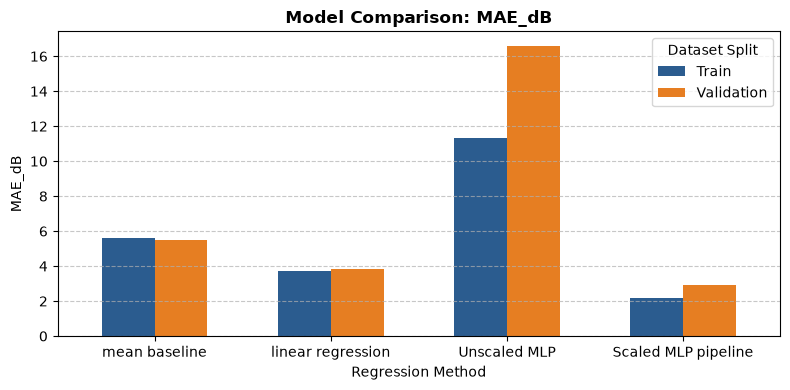

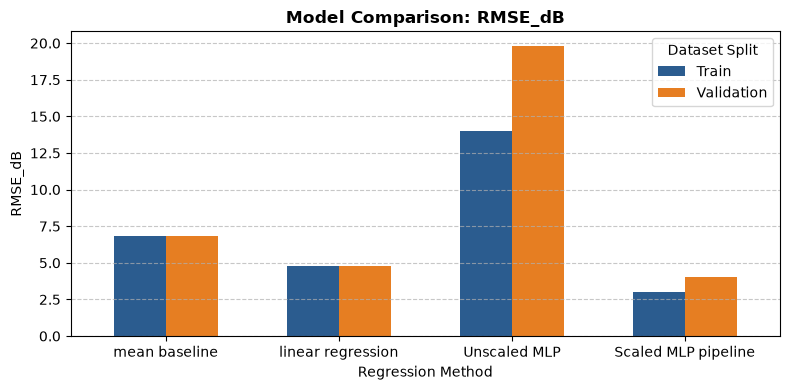

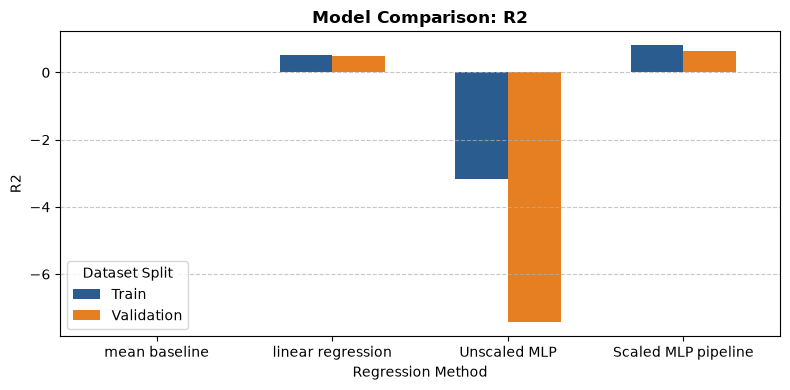

In [15]:
#Do metric comparison for validation data set
metric_comparison_val = pd.DataFrame({
    "mean baseline": regression_metrics(
        y_val,
        baseline_prediction,
    ),
    "linear regression": regression_metrics(
        y_val,
        val_pred_lr,
    ),
    "Unscaled MLP": regression_metrics(
        y_val,
        scaling_models["Unscaled MLP"].predict(X_val),
    ),
    "Scaled MLP pipeline": regression_metrics(
        y_val,
        scaling_models["Scaled MLP pipeline"].predict(X_val),
    ),
}).T
print("----Metrics for validation set----")
display(metric_comparison_val)

#Do metric comparison for train data set
metric_comparison_train = pd.DataFrame({
    "mean baseline": regression_metrics(
        y_train,
        np.full(len(y_train), y_train.mean()),
    ),
    "linear regression": regression_metrics(
        y_train,
        linear_model.predict(X_train),
    ),
    "Unscaled MLP": regression_metrics(
        y_train,
        scaling_models["Unscaled MLP"].predict(X_train),
    ),
    "Scaled MLP pipeline": regression_metrics(
        y_train,
        scaling_models["Scaled MLP pipeline"].predict(X_train),
    ),
}).T
print("----Metrics for train set----")
display(metric_comparison_train)

#Plot graphs to compare the performance value of train and validation data for each method
# 1. Extract the list of metric names
metrics_compare = metric_comparison_train.columns

# 2. Calculate the Generalization Gap Table directly from the separate tables
gap_table = pd.DataFrame(index=metric_comparison_train.index)
for m in metrics_compare:
    # Directly subtract train from validation using the individual DataFrames
    gap_table[m] = metric_comparison_val[m] - metric_comparison_train[m]

print("--- Generalization Gap Table (Validation minus Train) ---")
display(gap_table)

# 3. Loop through each metric and plot side-by-side histograms (bar charts)
for m in metrics_compare:
    fig, ax = plt.subplots(figsize=(8, 4))
    
    # Bundle Train and Validation metrics_compare for the current metric
    plot_df = pd.DataFrame({
        'Train': metric_comparison_train[m],
        'Validation': metric_comparison_val[m]
    })
    
    # Plot side-by-side bars
    plot_df.plot(kind='bar', ax=ax, color=['#2b5c8f', '#e67e22'], width=0.6)
    
    ax.set_title(f'Model Comparison: {m}', fontsize=12, fontweight='bold')
    ax.set_ylabel(m, fontsize=10)
    ax.set_xlabel('Regression Method', fontsize=10)
    ax.set_xticklabels(plot_df.index, rotation=0, ha='center')
    
    ax.legend(title='Dataset Split', frameon=True)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

Conduct different experiment set using different randomizer

In [17]:
seeds = [0, 123, 2026]

all_val_metrics = []

for seed in seeds:
    gss_val_new = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
    #Split the data and obtain the row idx for train and validation set
    train_new_idx, val_new_idx = next(gss_val_new.split(X_train_val, y_train_val, groups=groups[train_val_idx]))
    #Extract the data to their corresponding idx
    X_new_train, X_new_val = X_train_val.iloc[train_new_idx], X_train_val.iloc[val_new_idx]
    y_new_train, y_new_val= y_train_val.iloc[train_new_idx], y_train_val.iloc[val_new_idx]
    
    #refresh baseline
    baseline_pred = np.full(len(y_new_val), y_new_train.mean())
    
    #refresh linear regression
    linear_model_new = LinearRegression()
    linear_model_new.fit(X_new_train, y_new_train)
    
    #refresh neural network regression
    for label_new, model_new in scaling_models.items():
        model_new.fit(X_new_train, y_new_train)
    
    #construct the metric table for validation data set
    metric_comparison_val_new = pd.DataFrame({
        "mean baseline": regression_metrics(
            y_new_val,
            baseline_pred,
        ),
        "linear regression": regression_metrics(
            y_new_val,
            linear_model_new.predict(X_new_val),
        ),
        "Unscaled MLP": regression_metrics(
            y_new_val,
            scaling_models["Unscaled MLP"].predict(X_new_val),
        ),
        "Scaled MLP pipeline": regression_metrics(
            y_new_val,
            scaling_models["Scaled MLP pipeline"].predict(X_new_val),
        ),
    }).T
    
    #append to list
    all_val_metrics.append(metric_comparison_val_new)

display(pd.concat(all_val_metrics))
    
# 5. Average the results across all seeds for a robust final table
# pd.concat stacks them, groupby(level=0).mean() averages the metrics per model
final_averaged_metrics = pd.concat(all_val_metrics).groupby(level=0).mean()

print("\n---- Final Averaged Validation Metrics Across All Seeds ----")
display(final_averaged_metrics)

final_std_metrics = pd.concat(all_val_metrics).groupby(level=0).std()

print("\n---- Std of Validation Metrics Across All Seeds ----")
display(final_std_metrics)

,MAE_dB,RMSE_dB,R2
mean baseline,5.6734,6.9963,-0.0013
linear regression,3.6845,4.6442,0.5588
Unscaled MLP,8.4162,11.1316,-1.5347
Scaled MLP pipeline,2.7229,3.7080,0.7188
mean baseline,5.0677,6.1937,-0.0003
linear regression,3.6283,4.6503,0.4361
Unscaled MLP,21.5810,25.8790,-16.4639
Scaled MLP pipeline,3.0596,4.4002,0.4951
mean baseline,5.5719,6.8194,-0.0049
linear regression,3.5938,4.7015,0.5223



---- Final Averaged Validation Metrics Across All Seeds ----


,MAE_dB,RMSE_dB,R2
Scaled MLP pipeline,3.2620,4.4295,0.5447
Unscaled MLP,13.3448,16.3724,-6.7220
linear regression,3.6355,4.6653,0.5057
mean baseline,5.4377,6.6698,-0.0022



---- Std of Validation Metrics Across All Seeds ----


,MAE_dB,RMSE_dB,R2
Scaled MLP pipeline,0.6638,0.7366,0.1554
Unscaled MLP,7.1787,8.2474,8.4427
linear regression,0.0458,0.0315,0.0630
mean baseline,0.3244,0.4217,0.0024
